# Laboratorium 5: warstwy splotowe, operacja, parametry, interpretacja

Autor: Adam Pastuszak

Kod do sprawozdania, samo sprawozdanie jest w osobnym pliku PDF

## 1. Importy

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image, ImageOps
from torchvision import transforms

torch.manual_seed(0)
plt.rcParams["figure.dpi"] = 100
print("PyTorch:", torch.__version__)

PyTorch: 2.15.0+cu132


## 2. Własne zdjęcie w skali szarości

Zdjęcie: samochód przed halą magazynową, tablicę rejestracyjną zamazałem przed wczytaniem
W Colab wgraj plik zdjęcia i wpisz jego nazwę w FOTO
Zdjęcie jest obracane zgodnie z EXIF, zamieniane na skalę szarości i zmniejszane tak,
żeby krótszy bok miał 384 piksele, ten sam tensor gray jest używany we wszystkich punktach

rozmiar: (480, 384) | zakres jasności: 0.027 - 0.965


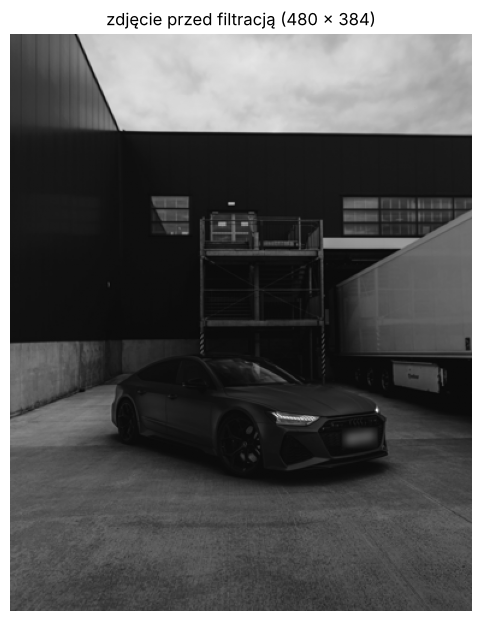

In [2]:
FOTO = "moje_zdjecie.jpg"
KROTSZY_BOK = 384

pil = ImageOps.exif_transpose(Image.open(FOTO)).convert("L")
skala = KROTSZY_BOK / min(pil.size)
pil = pil.resize((round(pil.width * skala), round(pil.height * skala)),
                 Image.BICUBIC)
gray = torch.from_numpy(np.array(pil)).float().div(255)[None, None]
H, W = gray.shape[-2:]
print("rozmiar:", (H, W), "| zakres jasności:",
      round(gray.min().item(), 3), "-", round(gray.max().item(), 3))

plt.figure(figsize=(6, 6 * H / W))
plt.imshow(gray[0, 0], cmap="gray", vmin=0, vmax=1)
plt.title(f"zdjęcie przed filtracją ({H} x {W})")
plt.axis("off")
plt.show()

## 3. Ręczne jądra przez F.conv2d

Sobel X i Y (pokazane ze znakiem, wspólna skala wokół zera), magnituda gradientu,
Sharpen i Laplacian 4-sąsiedni, padding 1 zachowuje rozmiar
Skale map krawędzi kończą się na 99,5 percentylu wartości z wnętrza obrazu, bo kilka
najmocniejszych krawędzi (dach na tle nieba) i brzegi z paddingu przyciemniłyby resztę

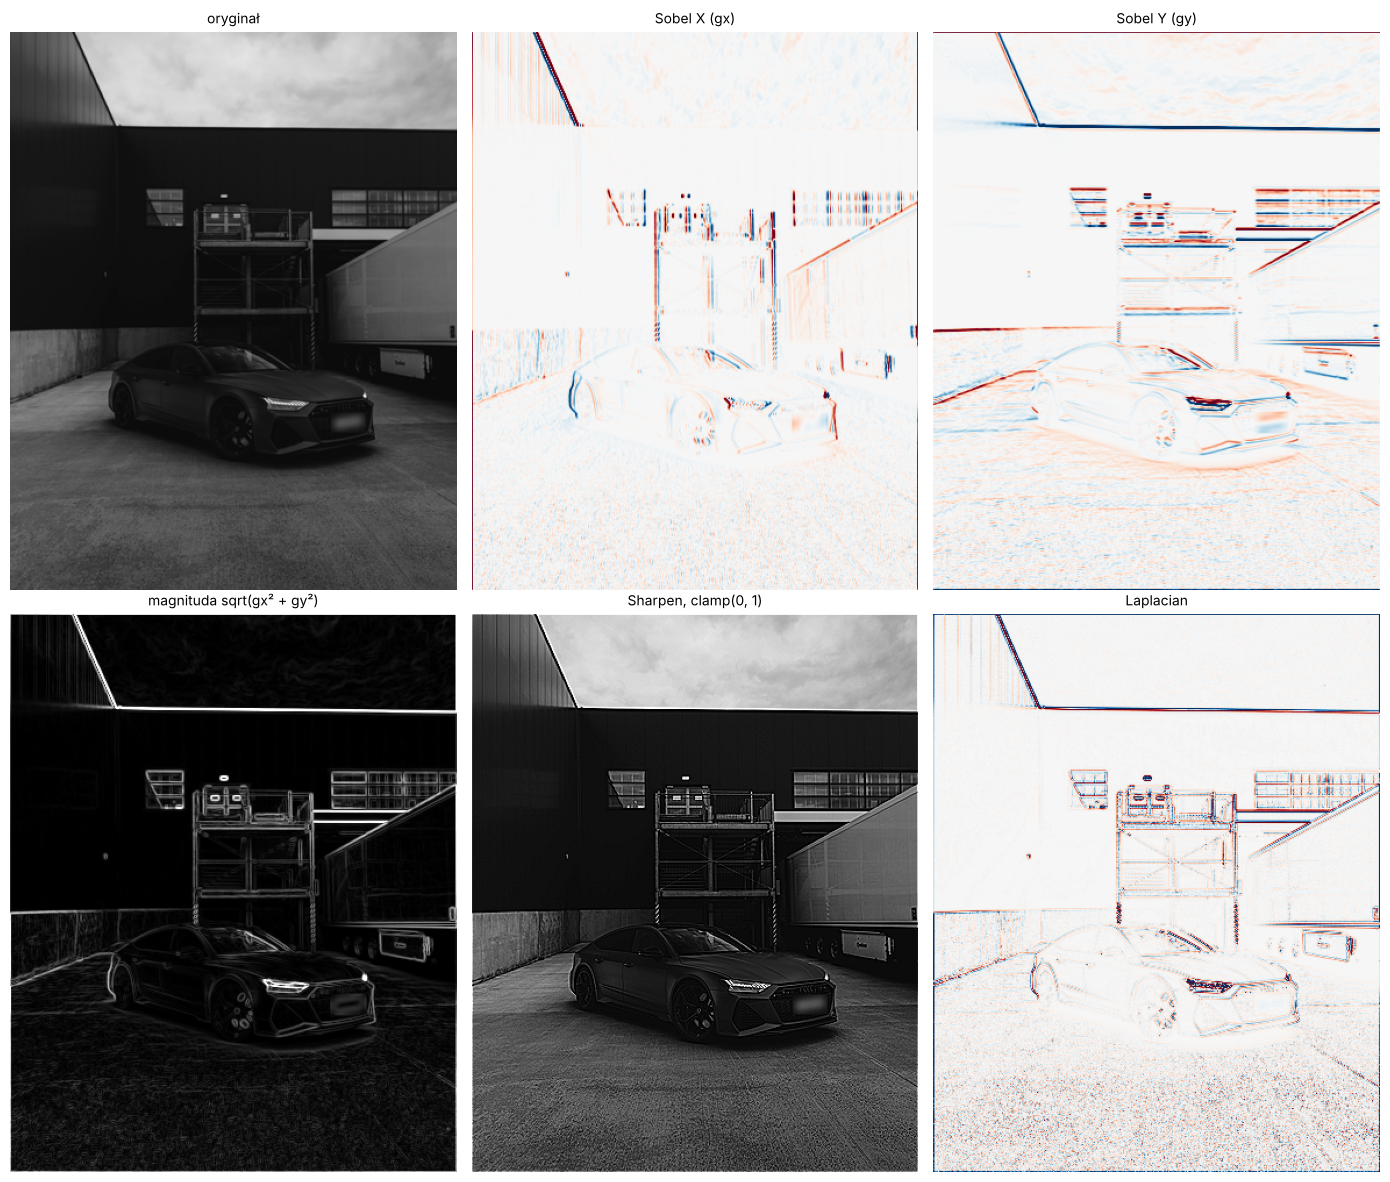

średnie |gx| = 0.0501, średnie |gy| = 0.0792
piksele z magnitudą > 0.5: 3.5%
Sharpen: odchylenie jasności 0.2371 -> 0.2500, wartości poza [0, 1]: 3.0% pikseli
Laplacian: średnie |odpowiedź| 0.0300


In [3]:
def kernel(t):
    return torch.tensor(t, dtype=torch.float32)[None, None]


JADRA = {
    "Sobel X": kernel([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "Sobel Y": kernel([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "Sharpen": kernel([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "Laplacian": kernel([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
}
wyn = {n: F.conv2d(gray, k, padding=1)[0, 0] for n, k in JADRA.items()}
gx, gy = wyn["Sobel X"], wyn["Sobel Y"]
mag = (gx ** 2 + gy ** 2).sqrt()


def okno_z_krawedziami(rozmiar, margines=8, krok=8):
    """Lewy górny róg okna o największej średniej magnitudzie gradientu."""
    m = mag[margines:H - margines, margines:W - margines]
    okna = F.avg_pool2d(m[None, None], rozmiar, stride=krok)[0, 0]
    iy, ix = divmod(int(okna.argmax()), okna.shape[1])
    return margines + iy * krok, margines + ix * krok


wnetrze = (slice(1, -1), slice(1, -1))


def gorna_granica(*mapy, q=0.995):
    # skala do 99,5 percentyla wnętrza, bez brzegów z paddingu
    return torch.quantile(torch.cat([m[wnetrze].abs().flatten()
                                     for m in mapy]), q).item()


lim = gorna_granica(gx, gy)
lap_lim = gorna_granica(wyn["Laplacian"])
panele = [
    ("oryginał", gray[0, 0], dict(cmap="gray", vmin=0, vmax=1)),
    ("Sobel X (gx)", gx, dict(cmap="RdBu_r", vmin=-lim, vmax=lim)),
    ("Sobel Y (gy)", gy, dict(cmap="RdBu_r", vmin=-lim, vmax=lim)),
    ("magnituda sqrt(gx² + gy²)", mag,
     dict(cmap="gray", vmin=0, vmax=gorna_granica(mag))),
    ("Sharpen, clamp(0, 1)", wyn["Sharpen"].clamp(0, 1),
     dict(cmap="gray", vmin=0, vmax=1)),
    ("Laplacian", wyn["Laplacian"],
     dict(cmap="RdBu_r", vmin=-lap_lim, vmax=lap_lim)),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 9.5 * H / W))
for ax, (tytul, m, kw) in zip(axes.flat, panele):
    ax.imshow(m, **kw)
    ax.set_title(tytul, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"średnie |gx| = {gx[wnetrze].abs().mean():.4f}, "
      f"średnie |gy| = {gy[wnetrze].abs().mean():.4f}")
frac = (mag[wnetrze] > 0.5).float().mean() * 100
print(f"piksele z magnitudą > 0.5: {frac:.1f}%")
ostr = wyn["Sharpen"]
print(f"Sharpen: odchylenie jasności {gray.std():.4f} -> "
      f"{ostr.clamp(0, 1).std():.4f}, wartości poza [0, 1]: "
      f"{((ostr < 0) | (ostr > 1)).float().mean() * 100:.1f}% pikseli")
lap_sr = wyn["Laplacian"][wnetrze].abs().mean()
print(f"Laplacian: średnie |odpowiedź| {lap_sr:.4f}")

## 4. Wzór na wymiary wyjścia a nn.Conv2d

out = floor((in + 2p − d(k − 1) − 1) / s) + 1, liczone osobno dla wysokości i szerokości zdjęcia

In [4]:
def out_dim(n, k, s=1, p=0, d=1):
    return (n + 2 * p - d * (k - 1) - 1) // s + 1


KONFIGI = [dict(k=3, s=1, p=1, d=1), dict(k=3, s=2, p=1, d=1),
           dict(k=5, s=1, p=0, d=1), dict(k=3, s=1, p=2, d=2),
           dict(k=7, s=2, p=3, d=1), dict(k=4, s=3, p=0, d=2)]
print(f"wejście: {H} x {W}")
print(f"{'k':>2} {'s':>2} {'p':>2} {'d':>2} | {'wzór H x W':>11} | "
      f"{'nn.Conv2d':>11} | zgodne")
tabela_wym = []
for c in KONFIGI:
    conv = nn.Conv2d(1, 8, kernel_size=c["k"], stride=c["s"],
                     padding=c["p"], dilation=c["d"])
    with torch.no_grad():
        real = tuple(conv(gray).shape[-2:])
    wzor = (out_dim(H, **c), out_dim(W, **c))
    tabela_wym.append((c, wzor, real))
    print(f"{c['k']:>2} {c['s']:>2} {c['p']:>2} {c['d']:>2} | "
          f"{wzor[0]:>4} x {wzor[1]:<4} | {real[0]:>4} x {real[1]:<4} | "
          f"{'tak' if wzor == real else 'NIE'}")

wejście: 480 x 384
 k  s  p  d |  wzór H x W |   nn.Conv2d | zgodne
 3  1  1  1 |  480 x 384  |  480 x 384  | tak
 3  2  1  1 |  240 x 192  |  240 x 192  | tak
 5  1  0  1 |  476 x 380  |  476 x 380  | tak
 3  1  2  2 |  480 x 384  |  480 x 384  | tak
 7  2  3  1 |  240 x 192  |  240 x 192  | tak
 4  3  0  2 |  158 x 126  |  158 x 126  | tak


## 5. Wpływ stride, padding i dilation

Ten sam Sobel X (wartość bezwzględna), zmienia się jeden parametr naraz względem s=1, p=1, d=1
Górny rząd: całe mapy (rozmiar w tytule), dolny rząd: ten sam fragment 64 x 64 zdjęcia
w każdej mapie, wybrany jako okno z największą średnią magnitudą gradientu

fragment: wiersze 136-200, kolumny 280-344


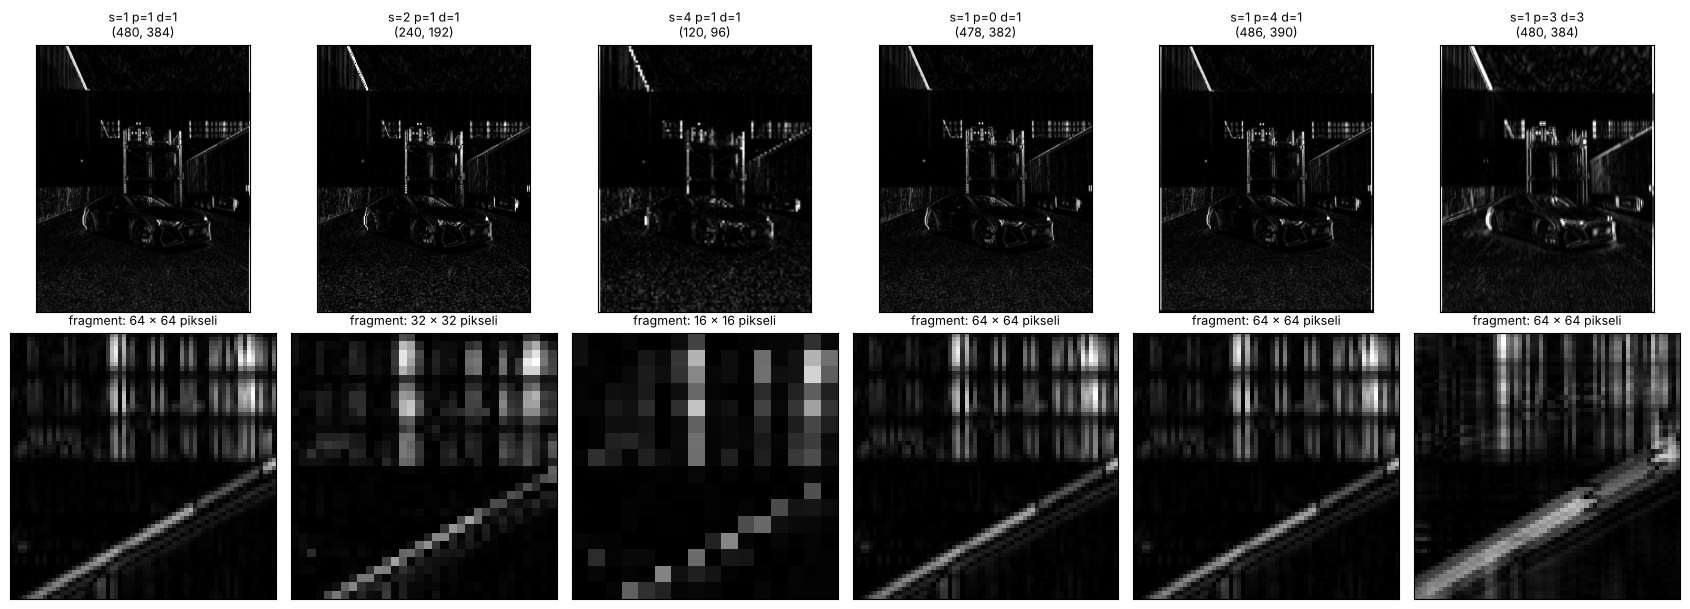

p=0: rozmiar (478, 382), średnie |gx| w skrajnej lewej kolumnie 0.030, w środku 0.044
p=1: rozmiar (480, 384), średnie |gx| w skrajnej lewej kolumnie 0.955, w środku 0.044
p=4: rozmiar (486, 390), średnie |gx| w skrajnej lewej kolumnie 0.000, w środku 0.043


In [5]:
USTAWIENIA = [dict(stride=1, padding=1, dilation=1),
              dict(stride=2, padding=1, dilation=1),
              dict(stride=4, padding=1, dilation=1),
              dict(stride=1, padding=0, dilation=1),
              dict(stride=1, padding=4, dilation=1),
              dict(stride=1, padding=3, dilation=3)]
sx = JADRA["Sobel X"]
R = 64
y0, x0 = okno_z_krawedziami(R)
print(f"fragment: wiersze {y0}-{y0 + R}, kolumny {x0}-{x0 + R}")
fig, axes = plt.subplots(2, len(USTAWIENIA), figsize=(17, 6.2))
for j, u in enumerate(USTAWIENIA):
    out = F.conv2d(gray, sx, **u)[0, 0].abs()
    s, p = u["stride"], u["padding"]
    axes[0, j].imshow(out, cmap="gray", vmin=0, vmax=lim)
    axes[0, j].set_title(f"s={s} p={p} d={u['dilation']}\n"
                         f"{tuple(out.shape)}", fontsize=9)
    # pozycja (y0, x0) zdjęcia w mapie wyjściowej: (y0 + p) / s
    a, b = (y0 + p) // s, (x0 + p) // s
    axes[1, j].imshow(out[a:a + R // s, b:b + R // s], cmap="gray",
                      vmin=0, vmax=lim, interpolation="nearest")
    axes[1, j].set_title(f"fragment: {R // s} x {R // s} pikseli",
                         fontsize=9)
    for ax in axes[:, j]:
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

for p in [0, 1, 4]:
    out = F.conv2d(gray, sx, padding=p)[0, 0].abs()
    print(f"p={p}: rozmiar {tuple(out.shape)}, średnie |gx| w skrajnej lewej "
          f"kolumnie {out[:, 0].mean():.3f}, w środku "
          f"{out[:, out.shape[1] // 2].mean():.3f}")

## 6. Mapy cech pretrenowanej sieci (ResNet-18, pierwsza warstwa splotowa)

ResNet-18 z torchvision z wagami wytrenowanymi na ImageNet-1k (timm, „ResNet strikes back” A1,
pobierane z GitHuba), szara skala powtórzona w trzech kanałach, krótszy bok 224 bez przycinania,
normalizacja ImageNet, mapy po ReLU nałożonym bezpośrednio na conv1

In [6]:
URL = ("https://github.com/huggingface/pytorch-image-models/releases/"
       "download/v0.1-rsb-weights/resnet18_a1_0-d63eafa0.pth")
model = torchvision.models.resnet18()
model.load_state_dict(torch.hub.load_state_dict_from_url(
    URL, map_location="cpu", check_hash=True))
model.eval()

prep = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
x = prep(pil.convert("RGB"))[None]  # ta sama szarość w 3 kanałach
with torch.no_grad():
    maps = torch.relu(model.conv1(x))[0]
Wc = model.conv1.weight.detach()  # [64, 3, 7, 7]
print("wejście:", tuple(x.shape), "| mapy conv1:", tuple(maps.shape))

# przy trzech jednakowych kanałach filtr działa jak suma swoich trzech macierzy
efekt = Wc.sum(1)
udzial = efekt.flatten(1).norm(dim=1) / Wc.flatten(1).norm(dim=1)
akt = maps.mean(dim=(1, 2))
norma = Wc.flatten(1).norm(dim=1)
print(f"średnia aktywacja map: min {akt.min():.3f}, mediana "
      f"{akt.median():.3f}, max {akt.max():.3f}")
pusty = akt < 0.01
martwy = norma < 0.05 * norma.max()
print(f"mapy prawie puste (średnia < 0.01): {pusty.sum().item()} z 64, "
      f"w tym filtry o prawie zerowych wagach: "
      f"{(pusty & martwy).sum().item()}, pozostałe puste mają medianę "
      f"udziału sumy kanałów {udzial[pusty & ~martwy].median():.2f}")
print(f"mediana udziału sumy kanałów: wszystkie filtry "
      f"{udzial.median():.2f}, 8 najaktywniejszych "
      f"{udzial[akt.argsort(descending=True)[:8]].median():.2f}")

wejście: (1, 3, 280, 224) | mapy conv1: (64, 140, 112)
średnia aktywacja map: min 0.000, mediana 0.336, max 23.224
mapy prawie puste (średnia < 0.01): 8 z 64, w tym filtry o prawie zerowych wagach: 5, pozostałe puste mają medianę udziału sumy kanałów 0.06
mediana udziału sumy kanałów: wszystkie filtry 1.59, 8 najaktywniejszych 1.60


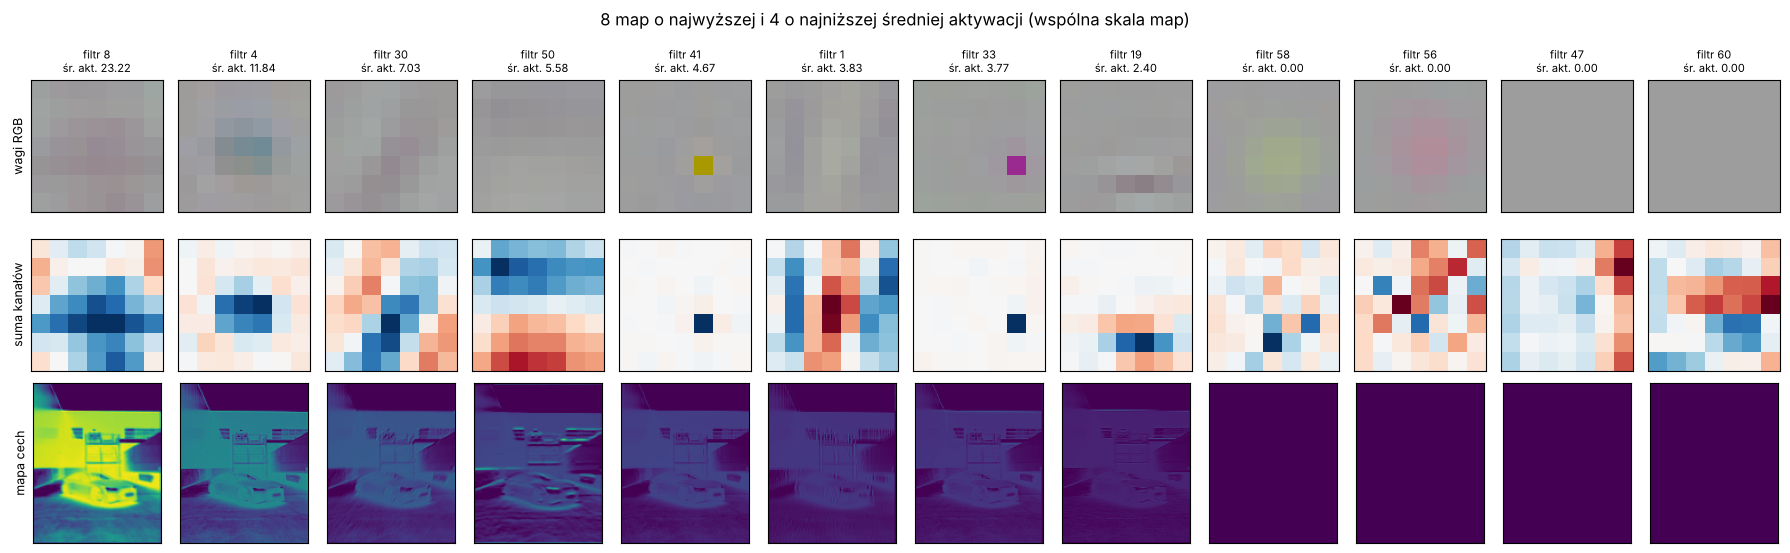

filtr śr. akt. norma wag udział sumy
    8   23.224     3.525        1.60
    4   11.838     4.269        1.49
   30    7.029     3.013        1.68
   50    5.582     2.822        1.69
   41    4.670     6.954        0.95
    1    3.828     2.685        1.60
   33    3.773     5.173        1.11
   19    2.402     3.142        1.69
   58    0.000     2.753        0.06
   56    0.000     2.823        0.04
   47    0.000     0.000        1.54
   60    0.000     0.000        1.44


In [7]:
def pokaz_filtr(ax, w):
    # wspólna skala dla wszystkich filtrów, jak w ćwiczeniu
    w = (w - Wc.min()) / (Wc.max() - Wc.min())
    ax.imshow(w.permute(1, 2, 0), interpolation="nearest")


wybrane = akt.argsort(descending=True)[:8].tolist()
najslabsze = akt.argsort()[:4].tolist()
pokaz = wybrane + najslabsze
fig, axes = plt.subplots(3, len(pokaz), figsize=(18, 5.6))
for j, i in enumerate(pokaz):
    pokaz_filtr(axes[0, j], Wc[i])
    e = efekt[i]
    axes[1, j].imshow(e, cmap="RdBu_r", vmin=-e.abs().max(),
                      vmax=e.abs().max(), interpolation="nearest")
    axes[2, j].imshow(maps[i], cmap="viridis", vmin=0,
                      vmax=maps[pokaz].max())
    axes[0, j].set_title(f"filtr {i}\nśr. akt. {akt[i]:.2f}", fontsize=8)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 0].set_ylabel("wagi RGB", fontsize=9)
axes[1, 0].set_ylabel("suma kanałów", fontsize=9)
axes[2, 0].set_ylabel("mapa cech", fontsize=9)
fig.suptitle("8 map o najwyższej i 4 o najniższej średniej aktywacji "
             "(wspólna skala map)")
plt.tight_layout()
plt.show()
print(f"{'filtr':>5s} {'śr. akt.':>8s} {'norma wag':>9s} {'udział sumy':>11s}")
for i in pokaz:
    print(f"{i:5d} {akt[i]:8.3f} {norma[i]:9.3f} {udzial[i]:11.2f}")

## 7. Box 3x3, Box 5x5 i Gaussian 5x5 na tym samym fragmencie

stride 1, dilation 1, padding k//2 (1, 2, 2) zachowuje rozmiar zdjęcia
Fragment 96 x 96 wybrany automatycznie jako okno z największą średnią magnitudą gradientu
(najwięcej krawędzi i detalu), wspólna skala jasności 0–1

Box 3x3       suma wag 1.000 | waga środka 0.1111 | udział środkowego 3x3 1.000 | odchylenie wag w osi 0.82 px
Box 5x5       suma wag 1.000 | waga środka 0.0400 | udział środkowego 3x3 0.360 | odchylenie wag w osi 1.41 px
Gaussian 5x5  suma wag 1.000 | waga środka 0.1406 | udział środkowego 3x3 0.766 | odchylenie wag w osi 1.00 px
fragment: wiersze 136-232, kolumny 248-344

wersja         max skok między sąsiednimi px  rozpiętość profilu  śr. |Laplacian| fragmentu
oryginał                               0.180               0.329                     0.0496
Box 3x3                                0.106               0.303                     0.0207
Box 5x5                                0.057               0.272                     0.0117
Gaussian 5x5                           0.095               0.290                     0.0176


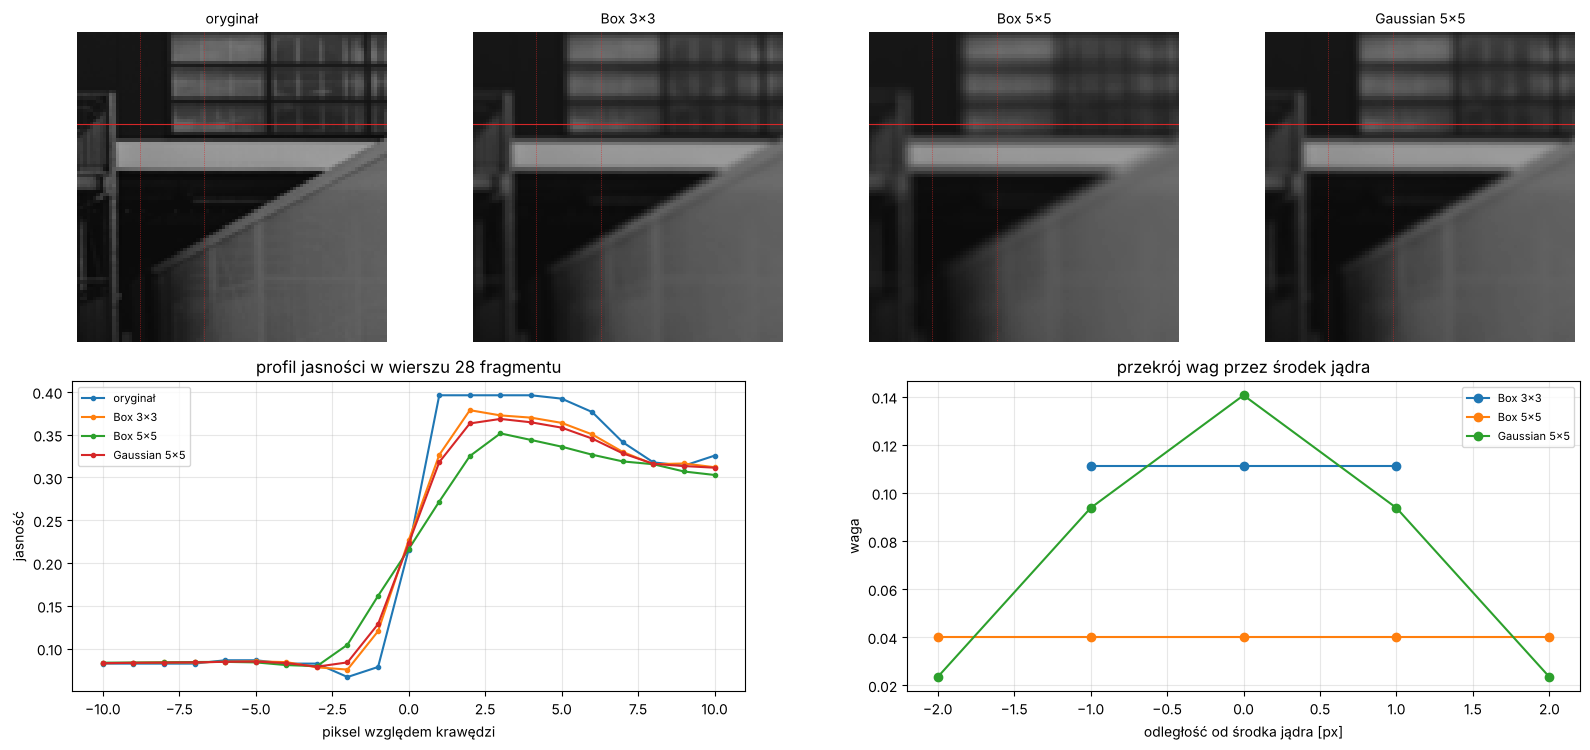

In [8]:
def gauss5():
    v = torch.tensor([1., 4., 6., 4., 1.])
    return (torch.outer(v, v) / 256)[None, None]


ROZMYCIA = {"Box 3x3": torch.ones(1, 1, 3, 3) / 9,
            "Box 5x5": torch.ones(1, 1, 5, 5) / 25,
            "Gaussian 5x5": gauss5()}
rozm = {}
for n, k in ROZMYCIA.items():
    out = F.conv2d(gray, k, stride=1, padding=k.shape[-1] // 2, dilation=1)
    assert out.shape == gray.shape
    rozm[n] = out[0, 0]
    w, c = k[0, 0], k.shape[-1] // 2
    sigma = float((w.sum(0) * (torch.arange(w.shape[0]) - c) ** 2).sum())
    sigma = sigma ** 0.5
    print(f"{n:13s} suma wag {w.sum():.3f} | waga środka {w[c, c]:.4f} | "
          f"udział środkowego 3x3 {w[c - 1:c + 2, c - 1:c + 2].sum():.3f} | "
          f"odchylenie wag w osi {sigma:.2f} px")

F_ROZ = 96
fy, fx = okno_z_krawedziami(F_ROZ)
print(f"fragment: wiersze {fy}-{fy + F_ROZ}, kolumny {fx}-{fx + F_ROZ}")

wersje = {"oryginał": gray[0, 0], **rozm}
frag = {n: v[fy:fy + F_ROZ, fx:fx + F_ROZ] for n, v in wersje.items()}

# profil w poprzek najsilniejszej pionowej krawędzi fragmentu
g = gx[fy:fy + F_ROZ, fx:fx + F_ROZ].abs()
g[:, :12] = 0
g[:, -12:] = 0
py, px = divmod(int(g.argmax()), F_ROZ)
xs = np.arange(px - 10, px + 11)


fig = plt.figure(figsize=(16, 7.6))
for j, (n, f) in enumerate(frag.items()):
    ax = fig.add_subplot(2, 4, j + 1)
    ax.imshow(f, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.axhline(py, color="tab:red", lw=0.8)
    ax.axvline(px - 10, color="tab:red", lw=0.5, ls=":")
    ax.axvline(px + 10, color="tab:red", lw=0.5, ls=":")
    ax.set_title(n, fontsize=10)
    ax.axis("off")
ax = fig.add_subplot(2, 2, 3)
print()
print(f"{'wersja':13s} {'max skok między sąsiednimi px':>30s} "
      f"{'rozpiętość profilu':>19s} {'śr. |Laplacian| fragmentu':>26s}")
for n, f in frag.items():
    prof = f[py, xs[0]:xs[-1] + 1].numpy()
    ax.plot(xs - px, prof, "o-", ms=3, label=n)
    skok = np.abs(np.diff(prof)).max()
    lap = F.conv2d(f[None, None], JADRA["Laplacian"])[0, 0].abs().mean()
    print(f"{n:13s} {skok:30.3f} {prof.max() - prof.min():19.3f} "
          f"{lap:26.4f}")
ax.set(xlabel="piksel względem krawędzi", ylabel="jasność",
       title=f"profil jasności w wierszu {py} fragmentu")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
ax = fig.add_subplot(2, 2, 4)
for n, k in ROZMYCIA.items():
    w = k[0, 0]
    srodek = w.shape[0] // 2
    ax.plot(np.arange(w.shape[0]) - srodek, w[srodek].numpy(), "o-",
            label=n)
ax.set(xlabel="odległość od środka jądra [px]", ylabel="waga",
       title="przekrój wag przez środek jądra")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()